# Nature Sonification Project

In this notebook you will find our sonfification project, in which we sonify a temperature dataset and layer it with natural sounds (rain, river, birds) and a nature-inspired beat to generate a piece of music. The notebook is organised as follows 
1. The code for each component layer is shown, where you can listen to each layer individually. 
2. An interactive cell which you can listen to all the layers simultaneously. You can change the scale used to select notes, the instruments used to play the melody and bass and also decrease or increase the volume of each sound layer. 

#### Importing the necessary libraries

In [1]:
# %pip install midiutil soundfile music21 # run this line in case some libraries are missing 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from midiutil import MIDIFile
from audiolazy_functions import str2midi, midi2str  # using premade functions from a sonification tutorial to convert notes to MIDI 
from IPython.display import Audio, HTML, display, clear_output
from music21 import chord, instrument, note, stream, tempo
import soundfile as sf
import base64, uuid
from pathlib import Path
import subprocess
import ipywidgets as w
import io

## Temperature Dataset Sonification

### Temperature Dataset Exploration and Visualisation
The data used for sonification in this project is from [this](https://www.knmi.nl/kennis-en-datacentrum/achtergrond/centraal-nederland-temperatuur-cnt) link, which contains records of the average temperature for every month in the Netherlands since 1906. 

In [2]:
df = pd.read_csv("temp_data.csv", skiprows=7, names=['years', 1,2,3,4,5,6,7,8,9,10,11,12])
df.head()

,years,1,2,3,4,5,6,7,8,9,10,11,12
0,1906,3.29,2.28,3.79,7.67,12.41,14.17,16.79,17.00,13.35,11.65,7.50,-0.28
1,1907,1.48,0.41,4.60,7.43,12.49,13.52,13.90,15.55,13.79,11.24,5.58,3.09
2,1908,-1.25,3.29,3.44,5.89,12.98,16.22,16.65,15.08,13.43,9.78,4.23,0.97
3,1909,0.54,0.30,2.97,8.55,11.30,12.94,14.58,16.31,13.02,10.95,3.89,3.01
4,1910,3.26,4.03,5.26,7.84,12.43,16.00,15.15,16.22,13.35,10.38,3.31,5.34


When we inspect the dataset, we can see that it is organised into rows of years and columns of months. If we visualise the data for one month across all years we get the following scatterplot: 

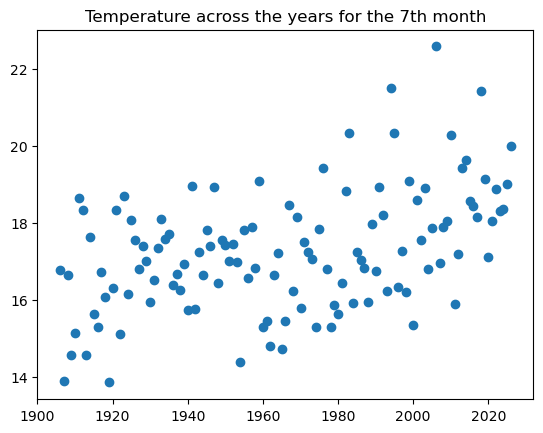

In [3]:
month = 7  # select a value ranging from 1-12 to look at the mean 
            # temperature for a specific month over the years

plt.scatter(df['years'].values, df[month].values)
plt.title(f'Temperature across the years for the {month}th month')
plt.show()

Over the last century, the mean temperature in the month of july appears to have slightly inccreased given the slight positive trend in the scatterplot. If we plot the monthly mean temperature for each year we get the following curves: 

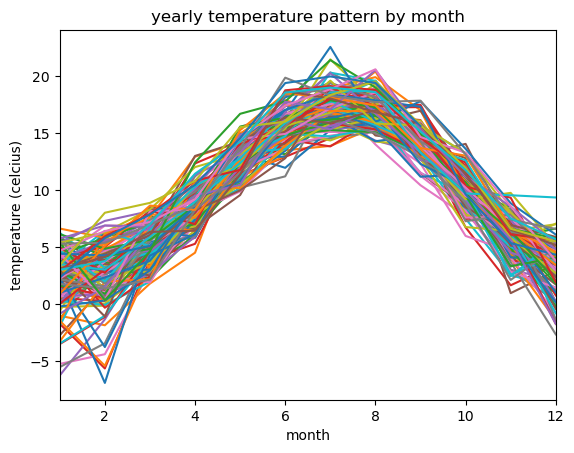

In [4]:
plt.plot(df.set_index('years').T)
plt.title('yearly temperature pattern by month')
plt.xlim((1,12))
plt.xlabel('month')
plt.ylabel('temperature (celcius)')
plt.show()

Despite the slight positive trend in mean temperature for july, we can see that across the years the temperature trend remains largely consistent. For our sonification, this suggests that this dataset will produce a relatively repetitive and consistent melody that cyclically increases and decreases over the months. Plotting every value in the dataset (each month, each year, temporally aligned) we can see the exact datapoints we are sonifying: 

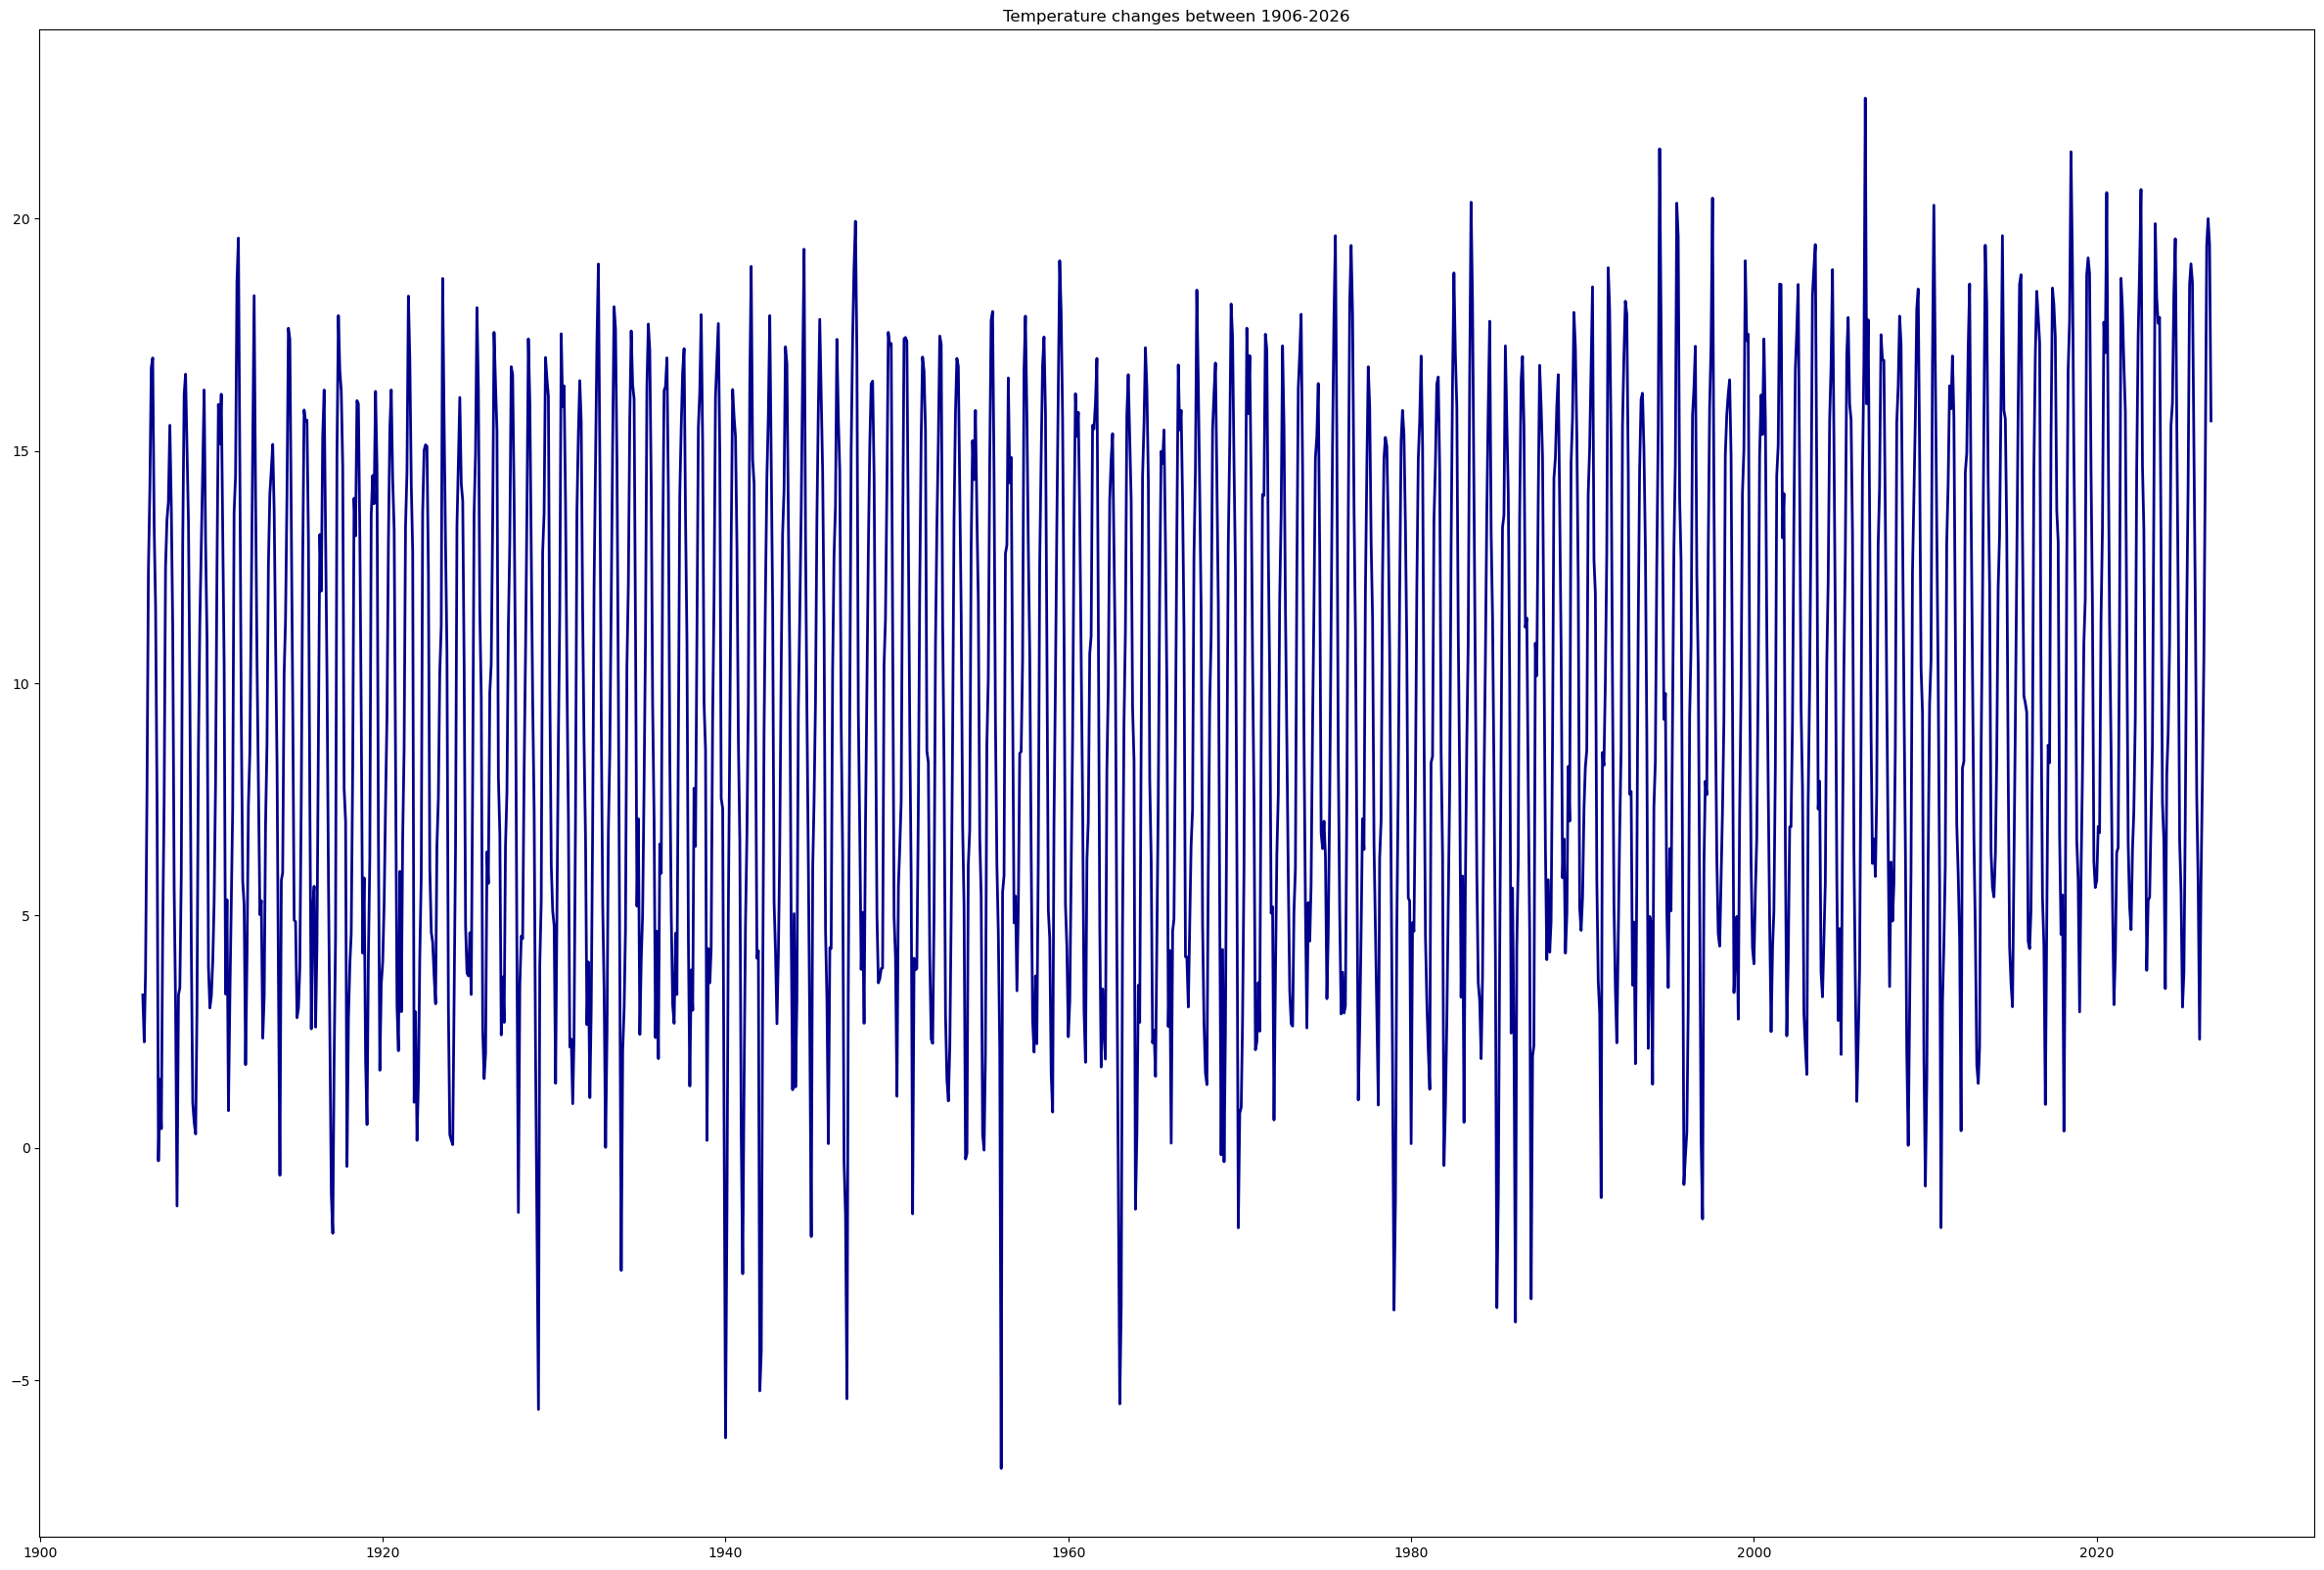

In [ ]:
df_long = df.melt(id_vars="years", var_name="month", value_name="temperature") 
df_long['date'] = pd.to_datetime(df_long[['years', 'month']].assign(day=1))
df_long = df_long.sort_values('date')

mini, maxi = (min(df_long['years']), max(df_long['years']))

plt.figure(figsize=(30,20))
plt.plot(df_long['date'], df_long['temperature'], color='darkblue', linewidth=2)
plt.title(f'Temperature changes between {mini}-{maxi}')
plt.show()

### Sonification Mapping Function 
The sonification of the temperature dataset was largely based on the procedure outlined in [this](https://medium.com/@astromattrusso/sonification-101-how-to-convert-data-into-music-with-python-71a6dd67751c) tutorial by Matt Russo. For our sonification, we use the same value mapping function from the tutorial. 

In [6]:
# function taken from sonification tutorial 
def map_value(value, min_value, max_value, min_result, max_result):
    '''maps value (or array of values) from one range to another'''
 
    result = min_result + (value - min_value)/(max_value - min_value)*(max_result - min_result)
    return result

To decide on the kind of mapping we wanted to do, we explored the values and ranges of values in our dataset: 

In [7]:
mins = []
maxs = []

# looping over the years and creating a list of minimal and maximal temperatures per year
for year in range(1906, 2027):
    temps = df[df['years']==year].values
    mins.append(min(temps[0][1:]))
    maxs.append(max(temps[0][1:]))

# selecting the minimal 
print(min(mins), max(maxs))

temp_range = max(maxs) - min(mins)
print(temp_range)

-6.9 22.59
29.490000000000002


The range of temepratures in our data is 29, from -6.9 to 22.59. We chose to round our monthly temperature datapoints so that we did not need to account for every decimal value in the data. Hence, our mapping would consist of 30 different values in the range of -7 and 23. 

In [8]:
processed_df = df.round()
long_proc_df = processed_df.melt(id_vars='years', var_name="month", value_name='temperature')
long_proc_df['date'] = pd.to_datetime(long_proc_df[['years', 'month']].assign(day=1))
long_proc_df = long_proc_df.sort_values('date')

temps = np.array(long_proc_df['temperature'])

max_temp = max(temps)
min_temp = min(temps)
range_temp = max_temp - min_temp
print(max_temp, min_temp, range_temp)

23.0 -7.0 30.0


We sonify our dataset by mapping the temperature values to MIDI notes using our mapping function and by basing the MIDI notes on different C-scales. Additionally, we add a sound for the yearly average per year, which acts as a bass beat in the melody. 

For the MIDI notes, we use premade functions developed by Danilo Bellini [(see github repository)](https://github.com/danilobellini/audiolazy/blob/master/audiolazy/lazy_midi.py
) which convert string notes to MIDI notes and vice versa. These functions make it easy to map our different C-scales to MIDI notes that can be listened to within the notebook. This is convenient to use with the *map_value* function, which takes numeric values as input and can hence be used to convert datapoints to MIDI notes. In the cell below, the variable *note_names* can be changed to the other scales defined above it. Running the cell outputs an interactive audio widget which can be played to hear 7 octaves of the different C-scales. 


**Why use different scales?**

While prototying the dataset sonification, we noticed that different scales greatly influenced the resulting musicality of the sound. Hence, we include a variety so that different scales can be experiemented with in the final product to illustrate how scale choice impacts the way the dataset is represented auditorily. 

In [ ]:
# yearly average 
yearly_avg = df.drop(columns='years').mean(axis=1).round()
yearly_avg_df = pd.DataFrame({'year': df['years'], 'average_temperature': yearly_avg})

# Function to expand each scale into 7 octaves 
def expand_scale(notes, octaves=range(1, 7)):
    return [f"{pitch}{octave}" for octave in octaves for pitch in notes]

# Major / major-type scales
c_major = expand_scale(["C", "D", "E", "F", "G", "A", "B"])
c_pentatonic = expand_scale(["C", "D", "E", "G", "A"])
c_lydian = expand_scale(["C", "D", "E", "F#", "G", "A", "B"])
c_mixolydian = expand_scale(["C", "D", "E", "F", "G", "A", "Bb"])

# Minor / minor-type scales
c_natural_minor = expand_scale(["C", "D", "Eb", "F", "G", "Ab", "Bb"])
c_minor_pentatonic = expand_scale(["C", "Eb", "F", "G", "Bb"])
c_minor_blues = expand_scale(["C", "Eb", "F", "Gb", "G", "Bb"])
c_dorian = expand_scale(["C", "D", "Eb", "F", "G", "A", "Bb"])
c_harmonic_minor = expand_scale(["C", "D", "Eb", "F", "G", "Ab", "B"])
c_melodic_minor = expand_scale(["C", "D", "Eb", "F", "G", "A", "B"])
c_phrygian = expand_scale(["C", "Db", "Eb", "F", "G", "Ab", "Bb"])

note_names = c_lydian # Pick the scale for this example section
midi_notes = (str2midi(n) for n in note_names)
midi_notes = list(midi_notes)
n_notes = len(note_names)

t_notes = [note.Note(n) for n in note_names]
stream_ = stream.Stream(t_notes)
stream_.show('midi', autoplay=True)

In [10]:
len(long_proc_df)

1452

Our dataset consists of 1452 elements, meaning we have 1452 months worth of data. Sonifying each month produces a very long track (around 12 minutes with 60 BPM), which is too long and demonstrates a very gradual increase and decrease in pitch. Instead of mapping each temperature datapoint to a note one to one, we chose to sample every third element of our dataset: every quarter temperature, 1 for each season. This cut our note count to 483 datapoints, which were mapped to one note each. 

In the cell below, the sonification of the quarterly dataset values can be listened to. Here, the Marimba is used for the melody (the quarterly notes) and the Bassoon is used for the annual bass sound. The scale that is used was defined in the previous cell to be the C-Lydian scale, but this can be changed manually for this part or using the user interface at the end for the combined endproduct.

In [ ]:
sampled_temps = temps[::3]  # Sample every quarter year
sampled_temps = sampled_temps[~np.isnan(sampled_temps)]  # Last three entries in the dataset are nan (oct, nov, dec 2026), so we remove them 
print(len(sampled_temps)) # Look at the new number of notes to play

scale_indices = np.rint(map_value(sampled_temps, min_temp, max_temp, 0, len(midi_notes) - 1)).astype(int) # Rescale temperature to note index 
mapped_temps = np.array(midi_notes)[scale_indices] # Map note index to previously defined melody notes in chosen scale 

yearly_avg_values = yearly_avg_df['average_temperature'].to_numpy() # Average yearly temperature as bassline

# Pick a set of bass notes, based on the presence of a Eb in the melody
melody_pitch_classes = {int(midi) % 12 for midi in midi_notes}
minor_third = str2midi('Eb3') % 12
bassline_pitch_names = ['C', 'Eb', 'F', 'G'] if minor_third in melody_pitch_classes else ['C', 'D', 'E', 'G', 'A'] 
bassline_octaves = range(3, 5)
bassline_midi_notes = np.array([
    str2midi(f'{pitch}{octave}')
    for octave in bassline_octaves
    for pitch in bassline_pitch_names
])

# Map every possible (rounded) yearly temperature to an index in the bass note list 
min_yearly_temp = np.nanmin(yearly_avg_values)
max_yearly_temp = np.nanmax(yearly_avg_values)
if min_yearly_temp == max_yearly_temp:
    bassline_midis = np.full(len(yearly_avg_values), bassline_midi_notes[len(bassline_midi_notes) // 2], dtype=int)
else:
    bassline_indices = np.rint(map_value(
        yearly_avg_values, min_yearly_temp, max_yearly_temp, 0, len(bassline_midi_notes) - 1
    )).astype(int)
    bassline_midis = bassline_midi_notes[bassline_indices]
bass_positions = np.arange(0, len(mapped_temps), 4)  

# Make playable music objects 
melody = stream.Part()
melody.insert(0, instrument.Marimba())
bassline = stream.Part()
bassline.insert(0, instrument.Bassoon())

for i, midi_value in enumerate(mapped_temps):
    melody.insert(i, note.Note(int(midi_value)))

for year_index, position in enumerate(bass_positions):
    bassline.insert(int(position), note.Note(int(bassline_midis[year_index])))

stream_ = stream.Score()
stream_.insert(0, melody)
stream_.insert(0, bassline)
stream_.show('midi', autoplay=True)

483


## Rain, water, wind
Our overarching aim was to create an aesthetically pleasing output that was a reflection of a nature-based soundscape. This required us to layer sounds that emanate from nature in order to provide a feel of the environmental surroundings. To this end, we decided to incorporate sounds of water and wind on top of our sonified melody. The purpose of this layer was to provide a background of natural noises that acts to shape the foundation of the sounds one would encounter in a forest. 

#### Audio Selection 
Two open-source datasets were used to find the sounds of running water, rain, wind, and thunder. These datasets can be accessed via the following links: [Environmental Sound Classification](https://www.kaggle.com/datasets/zekeriyabilgin/environmental-sound-classification-dataset?resource=download) and [FSC22 Dataset](https://www.kaggle.com/datasets/irmiot22/fsc22-dataset/data)

Each audio file was manually chosen from these datasets. The criteria for selection were just that the sounds were clear and could potentially be heard in a forest. In the end, we included sounds of gently flowing water “Flowing_Water”, more aggressively crashing water “Rushing_Water”, rainsounds “Rain”, wind blowing with intermittent bursts of thunder “Thunder”, pure wind sounds “Wind”, and wind sounds with sporadic bird song “Wind_Birds”. 

The original audio files can be found in the archive folder -> water_wind_layers -> audio_files

#### Modifiable Output
The output of the following code is each of the six audio files outlined above with a slider, such that each sound file’s volume can be interactively adjusted. This allows the listener to adapt the background tapestry of wind and water to their auditory preferences. 


In [12]:
SOUNDS_DIR = Path("audio_files")          
MIME = {".wav": "audio/wav", ".mp3": "audio/mpeg"}
START_VOLUME = 0.5


def build_mixer(folder=SOUNDS_DIR, start_volume=START_VOLUME):
    mixer_id = "m" + uuid.uuid4().hex[:8]   
    rows = []

    for path in sorted(Path(folder).iterdir()):
        mime = MIME.get(path.suffix.lower())
        if mime is None:
            continue                        
        b64 = base64.b64encode(path.read_bytes()).decode()
        uid = "a" + uuid.uuid4().hex[:8]
        rows.append(f"""
        <div style="margin:10px 0">
          <b>{path.stem}</b><br>
          <audio id="{uid}" controls loop
                 onloadedmetadata="this.volume={start_volume}"
                 src="data:{mime};base64,{b64}"></audio><br>
          Volume: <input type="range" min="0" max="1" step="0.01" value="{start_volume}"
            oninput="document.getElementById('{uid}').volume=this.value"
            style="width:250px">
        </div>""")

    if not rows:
        print(f"No .wav or .mp3 files found in {Path(folder).resolve()}")
        return

    display(HTML(f"""
    <div id="{mixer_id}" style="font-family:sans-serif">
      <button onclick="const c=document.querySelectorAll('#{mixer_id} audio');
                       const p=c[0].paused;
                       c.forEach(a => p ? a.play() : a.pause());
                       this.textContent = p ? 'Pause all' : 'Play all'">Play all</button>
      {''.join(rows)}
    </div>"""))


build_mixer()

## Nature Beats

This part generates a beat from naturalistic sounds instead of drums. This makes the generated music pieces sound more musical, while also adding onto the natural soundscape.


**The sounds.** Each sound is synthesized from scratch as a Python function with adjustable parameters, so every hit is built as follows:
- a *water drop* is a sine wave whose pitch quickly rises and then fades out;
- a *knock* is a short wooden tone plus a sharp noise snap;
- a *pebble* is a very short, bright click;
- a *leaf rustle* is noise that swells and fades;
- a *cricket* is three tiny high beeps in a row.


Every time a sound is played it is generated again with slightly different
random values (pitch, loudness and a few milliseconds of timing), so the beat never sounds exactly the same.


**The pattern.** A dictionary (`PATTERNS`) has the name of each sound as its key and a one-bar pattern as its value. In the pattern, `x` is a hit and `.` is a rest, and each character is a 16th note, so 16 characters make one bar. A second dictionary (`KIT`) links each name to its sound function and its volume.
Every hit is placed at its time on a silent track and an echo adds a sense of space.


In [13]:
BPM = 120
N_BARS = 8

# Per sound one row where you can write a x for a hit and a . as a rest, ervyry step is a 16th note
# 16 characters = one 4/4 bar
PATTERNS = {
    "drip":    "................",
    "knock":   "....x.......x...",
    "pebble":  "..x...x...x..x..",
    "rustle":  "x...x...x...x...",
    "cricket": "..x.......x.....",
}


SR = 22050
rng = np.random.default_rng(1)

def time(dur):
    return np.arange(int(dur * SR)) / SR

def noise(n):
    return np.diff(rng.normal(size=n + 1))

# the five percussion sounds
def drip():
    t = time(0.25)
    f0 = rng.uniform(200, 350)
    phase = 2 * np.pi * f0 * (t + 8 * t**2 / 2)
    return np.sin(phase) * np.exp(-22 * t) * np.minimum(t / 0.002, 1)

def knock():
    t = time(0.15)
    tone = np.sin(2 * np.pi * rng.uniform(600, 620) * t) * np.exp(-t / 0.025)
    snap = noise(len(t)) * np.exp(-t / 0.004)
    return tone + 0.7 * snap

def pebble():
    t = time(0.06)
    tone = np.sin(2 * np.pi * rng.uniform(2000, 3500) * t)
    return (0.5 * tone + 0.5 * noise(len(t))) * np.exp(-t / 0.006)

def rustle():
    t = time(0.12)
    return noise(len(t)) * np.hanning(len(t))

def cricket():
    y = np.zeros(int(0.12 * SR))
    t = time(0.012)
    f = rng.uniform(4000, 5000)
    for p in range(3):
        a = int(p * 0.025 * SR)
        y[a:a + len(t)] += np.sin(2 * np.pi * f * t) * np.hanning(len(t))
    return y

# sound function and volume for each row
KIT = {"drip": (drip, 1.0), "knock": (knock, 0.8), "pebble": (pebble, 0.4),
       "rustle": (rustle, 0.3), "cricket": (cricket, 0.35)}

# building the beat
steps = len(PATTERNS["drip"])                  # length of the pattern as steps per bar
assert all(len(p) == steps for p in PATTERNS.values()), "all patterns must have the same length"
step_dur = 60 / BPM / 4                        # seconds per 16th note
mix = np.zeros(int((N_BARS * steps * step_dur + 1) * SR))   # silent track

for bar in range(N_BARS):
    for name, pattern in PATTERNS.items():
        make, vol = KIT[name]
        for s, char in enumerate(pattern):
            if char != "x":
                continue
            sound = make()
            sound = sound / np.abs(sound).max()                   # same loudness for every sound
            t = (bar * steps + s) * step_dur + rng.normal(0, 0.008)   # time + tiny human wobble
            start = max(int(t * SR), 0)
            mix[start:start + len(sound)] += sound * vol * rng.uniform(0.7, 1.0)

# a little bit of echo
d = int(0.12 * SR)
mix = mix + 0.3 * np.concatenate([np.zeros(d), mix[:-d]])

mix = mix / np.abs(mix).max()
# sf.write("nature_beat.wav", mix, SR)
display(Audio(mix, rate=SR))

## Combined Generated Music 
The cell below combines each of the layers (nature beat, nature sounds and temperature sonficiation) into one musical piece. 

Each layer was produced with a different technique, hence in the code below the different layers of the music are brought together in a specific way. Firstly, the initial temperature sonification used the music21 library to turn the temperature data into musical notes: quarterly temperatures are mapped onto a chosen scale to form the melody, and yearly average temperatures are mapped onto a lower set of notes to form the bassline. In the code below, the melody and bassline parts are assigned to a General MIDI instrument and written to a MIDI file. This MIDI file contains the instructions for the sound, not the sound itself, so we used GeneralUser GS and FluidSynth to render the sonification into an audio file. [GeneralUser GS](https://schristiancollins.com/generaluser.php) is a soundfront of instrument samples and can be used to play MIDI files. [FluidSynth](https://www.fluidsynth.org/) is a real-time synthesiser that plays the notes using the soundfront provided by GeneralUser GS. 



In [ ]:
# Defining constant variables that contain file paths. The temperature sonifiction requires external tools
# Fluidsynth and a GeneralUser GS soundfront to turn MIDI note instructions into audio. 
# The paths for these tools are defined below, as well as the paths for the intermediate files they read and write. 
root = Path.cwd()
FLUIDSYNTH = str(root / "fluidsynth-v2.6.1-win10-x64-cpp11" / "bin" / "fluidsynth.exe")
SF2 = str(root / "GeneralUser-GS" / "GeneralUser-GS.sf2") # General MIDI soundfont (instrument samples)
MID = str(root / "sonification.mid") # notes written by the library music21 (no sound yet)
WAV = str(root / "sonification.wav") # audio rendered by FluidSynth


# Defining the scales, melody instruments and bass instruments that can be chosen by the user for the 
# temperature sonification. 

# SCALES contains the set of pitches the temperatures are mapped onto (the lists of notes are defined 
# above in the temperature sonification code)
SCALES = {
    "C-Major": c_major, "C-Pentatonic": c_pentatonic, "C-Lydian": c_lydian, "C-Mixolydian": c_mixolydian,
    "C-Natural minor": c_natural_minor, "C-Minor pentatonic": c_minor_pentatonic, "C-Minor blues": c_minor_blues,
    "C-Dorian": c_dorian, "C-Harmonic minor": c_harmonic_minor, "C-Melodic minor": c_melodic_minor,
    "C-Phrygian": c_phrygian
}

# MELODY_INSTRUMENTS & BASS_INSTRUMENTS contains the General MIDI program numbers (counted from 0), which 
# tell FluidSynth which sound from the soundfront plays the melody and bass notes. Here, "None" defines the option
# to leave either the melody or bass sound out of the piece.  
MELODY_INSTRUMENTS = {
    "Marimba": 12, "Vibraphone": 11, "Xylophone": 13, "Glockenspiel": 9, "Celesta": 8,
    "Music box": 10, "Piano": 0, "Harp": 46, "Nylon guitar": 24, "Kalimba": 108,
    "Flute": 73, "Clarinet": 71, "Oboe": 68, "Steel drums": 114,
    "Synth square lead": 80, "Synth calliope": 82,
    "Synth warm pad": 89, "Synth polysynth": 90, "Synth halo pad": 94,
    "No Melody": None,
}
BASS_INSTRUMENTS = {
    "Bassoon": 70, "Cello": 42, "Contrabass": 43, "Acoustic bass": 32,
    "Fretless bass": 35, "Tuba": 58, "Trombone": 57, 'No Bass': None,
}

# Defining functions to build the musical score. 
# make_instrument and build_score use the music21 library to turn the temperature data into 
# notes. The result is a music21 Score that can be written to a MIDI file. This step converts the data into MIDI,
# the subsequent functions and steps only deal with sound 
def make_instrument(program):
    # A generic music21 instrument tagged with a General MIDI program number. When the score is written to MIDI, this number selects the sound.
    inst = instrument.Instrument()
    inst.midiProgram = program
    return inst

def build_score(scale_notes, melody_program, bass_program):
    # Selecting quarterly temperatures for melody
    scale_midis = [str2midi(n) for n in scale_notes]  # note names -> MIDI numbers
    sampled = temps[::3]                              # every 3rd month = quarterly (1449 -> 483 notes)
    sampled = sampled[~np.isnan(sampled)]             # drop the empty future months (oct, nov, dec 2026)
    
    # Mapping the temperatures to the scale: the coldest temperature maps to the lowest scale note, the warmest to the highest
    idx = np.rint(map_value(sampled, min_temp, max_temp, 0, len(scale_midis) - 1)).astype(int)
    mapped = np.array(scale_midis)[idx]

    # Selecting yearly average temperatures for bassline
    # The pool of bass notes follows the scale's character: minor-like scales (containing Eb) get minor chord tones, the others get major ones.
    pitch_classes = {m % 12 for m in scale_midis}
    names = ['C', 'Eb', 'F', 'G'] if str2midi('Eb3') % 12 in pitch_classes else ['C', 'D', 'E', 'G', 'A']
    pool = np.array([str2midi(f'{p}{o}') for o in range(3, 5) for p in names])
    lo, hi = np.nanmin(yearly_avg_values), np.nanmax(yearly_avg_values)
    if lo == hi:
        bass = np.full(len(yearly_avg_values), pool[len(pool) // 2], dtype=int)   # no variation: one middle note
    else:
        bass = pool[np.rint(map_value(yearly_avg_values, lo, hi, 0, len(pool) - 1)).astype(int)]
    positions = np.arange(0, len(mapped), 4)                # one bass note every 4 melody notes (= one bar)

    # An empty score would render as near-silence, so at least one part is required
    if melody_program is None and bass_program is None:
        raise ValueError("Select at least one of melody or bass.")

    # Putting together the score 
    score = stream.Score()
    score.insert(0, tempo.MetronomeMark(number=BPM))  # same BPM as the nature beat -> layers stay in time

    if melody_program is not None:
        mel_part = stream.Part()
        mel_part.insert(0, make_instrument(melody_program))
        for i, m in enumerate(mapped):
            mel_part.insert(i, note.Note(int(m)))  # one melody note per beat
        score.insert(0, mel_part)

    if bass_program is not None:
        bass_part = stream.Part()
        bass_part.insert(0, make_instrument(bass_program))
        for m, p in zip(bass, positions):
            bass_part.insert(int(p), note.Note(int(m))) # one bass note per bar
        score.insert(0, bass_part)

    return score

# Rendering the score to audio using FluidSynth, which plays the MIDI file note instructions using the 
# soundfront's instrument samples. FluidSynth also writes a new .wav file, which we then use as one 
# audio layer in the whole musical piece. 
def render_song(scale_name, melody_name, bass_name):
    score = build_score(SCALES[scale_name], MELODY_INSTRUMENTS[melody_name], BASS_INSTRUMENTS[bass_name])
    score.write("midi", fp=MID)
    # Options (-F output file, -r sample rate) must come BEFORE the soundfont and MIDI file.
    # The sample rate SR matches the nature beat, so both layers share one audio format.
    res = subprocess.run([FLUIDSYNTH, "-ni", "-F", WAV, "-r", str(SR), SF2, MID],
                         capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(res.stdout + res.stderr)         # shows FluidSynth's own error message
    y, sr_ = sf.read(WAV)
    if y.ndim > 1:
        y = y.mean(axis=1)                                  # stereo --> mono keeps the embedded file smaller
    return y / np.abs(y).max(), sr_                         # normalising so that the loudest peak is 1.0


# Combining all layers using an HTML block: each layer (nature sounds, nature beat, sonification)
# get their own <audio> player with a volume slider. 
def wav_b64(y, sr):
    # Encodes a NumPy audio array as a base64 WAV string, so the generated audio (sonification, nature beat) 
    # can be embedded directly in the HTML player.
    buf = io.BytesIO()
    sf.write(buf, y, sr, format="WAV", subtype="PCM_16")
    return base64.b64encode(buf.getvalue()).decode()

def mixer_html(extra_tracks=(), folder=SOUNDS_DIR, start_volume=START_VOLUME):
    mixer_id = "m" + uuid.uuid4().hex[:8] # unique id so the buttons only control this mixer
    sources = []

    # Nature sounds layer: accessing the prerecorded nature sounds from the audio folder
    for path in sorted(Path(folder).iterdir()):
        mime = MIME.get(path.suffix.lower())
        if mime:
            sources.append((path.stem, mime, base64.b64encode(path.read_bytes()).decode()))

    # Sonification and Nature Beat layers: the generated tracks are passed to the HTML block 
    for name, y, sr_ in extra_tracks:
        sources.append((name, "audio/wav", wav_b64(y, sr_)))

    # One player+volume slider per layer. Shorter tracks are repeated 
    rows = []
    for name, mime, b64 in sources:
        uid = "a" + uuid.uuid4().hex[:8]
        rows.append(f"""
        <div style="margin:10px 0">
          <b>{name}</b><br>
          <audio id="{uid}" controls loop preload="auto" 
                 onloadedmetadata="this.volume={start_volume}"
                 src="data:{mime};base64,{b64}"></audio><br>
          Volume: <input type="range" min="0" max="1" step="0.01" value="{start_volume}"
            oninput="document.getElementById('{uid}').volume=this.value" style="width:250px">
        </div>""")

    # "Play all" resets every player to 0:00 and starts them together while "Pause all" stops them
    return f"""
    <div id="{mixer_id}" style="font-family:sans-serif">
      <button onclick="document.querySelectorAll('#{mixer_id} audio').forEach(a => {{a.currentTime=0; a.play()}})">Play all (from start)</button>
      <button onclick="document.querySelectorAll('#{mixer_id} audio').forEach(a => a.pause())">Pause all</button>
      {''.join(rows)}
    </div>"""


# Adding interactive controls that let the user select the scalle, melody instrument and bass instrument
# the render button regenerates the sonification and rebuilds the mixer, the mixer lives in one HTML widget whose 
# content is replaced on every render. 
scale_dd   = w.Dropdown(options=list(SCALES), value="Lydian", description="Scale:")
melody_dd  = w.Dropdown(options=list(MELODY_INSTRUMENTS), value="Marimba", description="Melody:")
bass_dd    = w.Dropdown(options=list(BASS_INSTRUMENTS), value="Bassoon", description="Bass:")
render_btn = w.Button(description="Render", button_style="primary", icon="play")
status     = w.Label(value="")
mixer_box  = w.HTML(value="") # the single place the mixer is shown

def on_render(_):
    render_btn.disabled = True    # prevents double clicks while rendering
    status.value = "Rendering..."
    mixer_box.value = ""          # removes the old mixer (and stops its audio)
    try:
        # layer 1: build the sonification with the chosen scale and instruments
        sonif, sr_ = render_song(scale_dd.value, melody_dd.value, bass_dd.value)

        # layer 2: the nature beat (from the earlier cell) is cut to one bar-aligned loop, then repeated until it 
        # is as long as the sonification, so both layers stay in step
        beat_loop = mix[:int(N_BARS * steps * step_dur * SR)]
        beat_full = np.tile(beat_loop, int(np.ceil(len(sonif) / len(beat_loop))))[:len(sonif)]

        # combine: sonification + nature beat + the nature sound files, all in one mixer
        mixer_box.value = mixer_html(extra_tracks=[("Temperature Sonification", sonif, sr_),
                                                   ("Nature Beat", beat_full, SR)])
        status.value = f"{scale_dd.value} | {melody_dd.value} | {bass_dd.value}"
    except Exception as e:
        status.value = f"Render failed: {e}" # errors show in the label instead of crashing the cell
    render_btn.disabled = False

render_btn.on_click(on_render)

# Displaying the UI 
ui = w.VBox([w.HBox([scale_dd, melody_dd, bass_dd]), w.HBox([render_btn, status]), mixer_box])
print('Interactive UI -- How to use:\n1. Select a scale and instruments for the Melody and Bass.\n2. Click on "Render" and wait for the slider widgets to appear.\n3. Click "Play all (from start)" and listen to the music! Play around with the volume sliders of each component sound!\n\nIf you want to try different instruments or scales, reselect them and re-render the page')
display(ui)

Interactive UI -- How to use:
1. Select a scale and instruments for the Melody and Bass.
2. Click on "Render" and wait for the slider widgets to appear.
3. Click "Play all (from start)" and listen to the music! Play around with the volume sliders of each component sound!

If you want to try different instruments or scales, reselect them and re-render the page


### Original Combination (with regular synth notes)

In [16]:
# # 1. Render the temperature sonification (cell 5) to audio instead of a MIDI widget
# def midi_to_hz(m):
#     return 440.0 * 2 ** ((np.asarray(m) - 69) / 12)

# def synth_note(midi, dur, harmonics, decay, sr=SR):
#     t = np.arange(int(dur * sr)) / sr
#     f = midi_to_hz(midi)
#     w = sum(a * np.sin(2 * np.pi * f * (k + 1) * t) for k, a in enumerate(harmonics))
#     return w * np.exp(-t / decay) * np.minimum(t / 0.005, 1)   # decay + click-free attack

# def render_sonification(melody_midis, bass_midis, bass_positions, note_dur=0.5, sr=SR):
#     y = np.zeros(int((len(melody_midis) * note_dur + 3) * sr))
#     for i, m in enumerate(melody_midis):                        # marimba-ish melody
#         s = synth_note(m, 1.5, [1, 0.4, 0.2], 0.3)
#         a = int(i * note_dur * sr)
#         y[a:a + len(s)] += 0.5 * s
#     for m, p in zip(bass_midis, bass_positions):                # bassoon-ish bassline
#         s = synth_note(m, 3.0, [1, 0.5], 1.0)
#         a = int(p * note_dur * sr)
#         y[a:a + len(s)] += 0.6 * s
#     return y / np.abs(y).max()

# sonif = render_sonification(mapped_temps, bassline_midis, bass_positions, note_dur=60/BPM)
# beat_loop = mix[:int(N_BARS * steps * step_dur * SR)]   # bar-aligned so it loops cleanly
# beat_full = np.tile(beat_loop, int(np.ceil(len(sonif) / len(beat_loop))))[:len(sonif)]


# # 2. One mixer with every track: ambient files + beat + sonification
# def wav_b64(y, sr):
#     buf = io.BytesIO()
#     sf.write(buf, y, sr, format="WAV", subtype="PCM_16")
#     return base64.b64encode(buf.getvalue()).decode()

# def build_mixer(folder=SOUNDS_DIR, start_volume=START_VOLUME, extra_tracks=()):
#     mixer_id = "m" + uuid.uuid4().hex[:8]
#     sources = []
#     for path in sorted(Path(folder).iterdir()):
#         mime = MIME.get(path.suffix.lower())
#         if mime:
#             sources.append((path.stem, mime, base64.b64encode(path.read_bytes()).decode()))
#     for name, y, sr in extra_tracks:
#         sources.append((name, "audio/wav", wav_b64(y, sr)))

#     rows = []
#     for name, mime, b64 in sources:
#         uid = "a" + uuid.uuid4().hex[:8]
#         rows.append(f"""
#         <div style="margin:10px 0">
#           <b>{name}</b><br>
#           <audio id="{uid}" controls loop preload="auto"
#                  onloadedmetadata="this.volume={start_volume}"
#                  src="data:{mime};base64,{b64}"></audio><br>
#           Volume: <input type="range" min="0" max="1" step="0.01" value="{start_volume}"
#             oninput="document.getElementById('{uid}').volume=this.value" style="width:250px">
#         </div>""")

#     display(HTML(f"""
#     <div id="{mixer_id}" style="font-family:sans-serif">
#       <button onclick="document.querySelectorAll('#{mixer_id} audio').forEach(a => {{a.currentTime=0; a.play()}})">Play all (from start)</button>
#       <button onclick="document.querySelectorAll('#{mixer_id} audio').forEach(a => a.pause())">Pause all</button>
#       {''.join(rows)}
#     </div>"""))

# build_mixer(extra_tracks=[("temperature sonification", sonif, SR),
#                           ("nature beat", beat_full, SR)])